# Check the export

A quick look at what `run_exporting_pipeline.py` wrote to `<neuropixels_dir>/<export_folder_name>/export/`.
Set the two file paths in the first cell; nothing else is needed -- no session config, no
`spikesorting` package, just h5py:

1. **`<recording>.sorted_spikes.mat`** -- how many units, how many single units (`good`) and
   multi-units (`mua`), where they sit on the probe (each unit's mean waveform at Kilosort's own
   spike position, as `export/figures/overview.pdf` draws it), their firing rates, and a few
   random examples;
2. **`<run>.lfp.mat`** (when the session has `export_lfp: true`) -- a few LFP traces and their
   spectrogram.

Plain h5py: a v7.3 `.mat` is an HDF5 file. Two things to know when reading one in Python --
MATLAB stores every array **transposed** (h5py's shape is MATLAB's reversed), and text as
**character codes** (`"".join(map(chr, ...))` turns it back into a string).

In [46]:
import json
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import signal

# ---------------- edit these: the two exported files ----------------
# Both sit in <neuropixels_dir>/kilosort4/export/ (or wherever that folder was copied).
SPIKES_MAT = Path(r"Z:/Monkey Athos/2026-11-10/Athos_20261110_t1310_d6700_J4_exp_g0/Athos_20261110_t1310_d6700_J4_exp_g0_imec0/kilosort4_dredge/export/Athos_20261110_t1310_d6700_J4_exp_g0_t0.imec0.ap.sorted_spikes.mat")
LFP_MAT = Path(r"Z:/Monkey Athos/2026-11-10/Athos_20261110_t1310_d6700_J4_exp_g0/Athos_20261110_t1310_d6700_J4_exp_g0_imec0/kilosort4_dredge/export/Athos_20261110_t1310_d6700_J4_exp_g0_t0.imec0.lf.lfp.mat")   # or None: no LFP section

for path in (SPIKES_MAT, LFP_MAT):
    if path is not None:
        print(f"{path.name:60} {path.stat().st_size / 1e6:10.1f} MB")

Athos_20261110_t1310_d6700_J4_exp_g0_t0.imec0.ap.sorted_spikes.mat      540.6 MB
Athos_20261110_t1310_d6700_J4_exp_g0_t0.imec0.lf.lfp.mat         6753.0 MB


## 1. Load the sorted spikes

`sorted_spikes` has one entry per **spike** (`TimeStamps` in s, `Unit`, `Channel`) and an `info`
struct with one entry per **unit** (`Unit_No`, `Label`, `KSLabel`, `Channel_Number`, `n_spikes`).
`MeanWaveform`/`StdWaveform` hold each unit's measured mean ± std on its peak channel. Units Phy
labelled `noise` are not exported.

In [47]:
# Every file is opened in a `with` block and closed when the block ends. An open
# h5py file stays locked for as long as this notebook's kernel runs, and the
# exporting pipeline then cannot rewrite it ("unable to lock file").
with h5py.File(SPIKES_MAT, "r") as f:
    s = f["sorted_spikes"]
    print(SPIKES_MAT.name)
    for name in list(s) + [f"info/{k}" for k in s["info"]]:
        if isinstance(s[name], h5py.Dataset):
            print(f"  {name:28} MATLAB size {' x '.join(map(str, s[name].shape[::-1]))}")

Athos_20261110_t1310_d6700_J4_exp_g0_t0.imec0.ap.sorted_spikes.mat
  Channel                      MATLAB size 1 x 16876063
  MeanWaveform                 MATLAB size 962 x 60
  MeanWaveformUnit             MATLAB size 1 x 2
  StdWaveform                  MATLAB size 962 x 60
  TimeRes                      MATLAB size 1 x 1
  TimeStamps                   MATLAB size 1 x 16876063
  Unit                         MATLAB size 1 x 16876063
  spike_sample                 MATLAB size 1 x 16876063
  window_ms                    MATLAB size 1 x 1
  info/Channel_Number          MATLAB size 1 x 962
  info/KSLabel                 MATLAB size 1 x 6003
  info/Label                   MATLAB size 1 x 6003
  info/MeanWaveform_Unit_No    MATLAB size 1 x 962
  info/Unit_No                 MATLAB size 1 x 962
  info/ViolationRate           MATLAB size 1 x 962
  info/n_spikes                MATLAB size 1 x 962
  info/samplingrate            MATLAB size 1 x 1
  info/session                 MATLAB size 1 x 20


In [48]:
with h5py.File(SPIKES_MAT, "r") as f:                # read into memory, then closed
    s = f["sorted_spikes"]
    times = s["TimeStamps"][()].ravel()                  # every spike, seconds
    spike_unit = s["Unit"][()].ravel().astype(int)

    unit_ids = s["info/Unit_No"][()].ravel().astype(int)
    labels = "".join(map(chr, s["info/Label"][()].ravel())).split(" | ")
    ks_labels = "".join(map(chr, s["info/KSLabel"][()].ravel())).split(" | ")
    channels = s["info/Channel_Number"][()].ravel()
    n_spikes = s["info/n_spikes"][()].ravel().astype(int)
    timebase = "".join(map(chr, s["info/timebase"][()].ravel()))
    fs = s["TimeRes"][()].item()

    has_waves = "MeanWaveform" in s                  # each unit's measured mean, for section 5
    if has_waves:
        mean_wave = s["MeanWaveform"][()]              # (samples, units): MATLAB's nUnits x nSamp
        std_wave = s["StdWaveform"][()]
        wave_ids = list(s["info/MeanWaveform_Unit_No"][()].ravel().astype(int))
        wave_unit = "".join(map(chr, s["MeanWaveformUnit"][()].ravel()))

# Firing rates divide by the recording length the export used, when the manifest beside it says it.
manifest = SPIKES_MAT.parent / "sorting_summary_info.json"
window = json.loads(manifest.read_text()).get("recording_window", {}) if manifest.exists() else {}
duration_s = window.get("duration_s", times.max() - times.min())

print(f"{times.size:,} spikes, {unit_ids.size} units, timebase {timebase}")
print(f"recording: {duration_s / 60:.1f} min ({window.get('from', 'span of the spikes')})")

16,876,063 spikes, 962 units, timebase blackrock
recording: 127.6 min (samples sorted)


## 2. How many units, and what kind

`good` = single unit, `mua` = multi-unit. A unit nobody curated in Phy keeps Kilosort's own label.

kind
multi-unit     728
single unit    234 

KSLabel          good  mua
label (curated)           
good              234    0
mua                 0  728


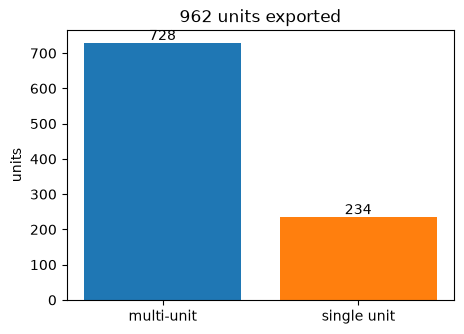

In [49]:
units = pd.DataFrame({
    "unit_id": unit_ids,
    "label": labels,
    "ks_label": ks_labels,
    "channel": channels,
    "n_spikes": n_spikes,
    "rate_hz": n_spikes / duration_s,
})
units["kind"] = units["label"].map({"good": "single unit", "mua": "multi-unit"}).fillna(units["label"])

print(units["kind"].value_counts().to_string(), "\n")
print(pd.crosstab(units["label"], units["ks_label"], rownames=["label (curated)"], colnames=["KSLabel"]))

counts = units["kind"].value_counts()
plt.figure(figsize=(5, 3.5))
bars = plt.bar(counts.index, counts.values, color=[f"C{i}" for i in range(len(counts))])
plt.bar_label(bars)
plt.ylabel("units")
plt.title(f"{len(units)} units exported")
plt.show()

## 3. The probe overview: every unit where it sits

The waveform pages of `export/figures/overview.pdf`, redrawn from three files in the export folder,
so they work wherever it is copied -- no Kilosort folder needed:

- each unit's measured mean (`MeanWaveform`) from `*.sorted_spikes.mat`;
- where it sits and its Phy label from `units.csv` (`x_um`, `y_um`: the centre the pipeline drew
  it at, from Kilosort's own spike positions);
- the electrodes from `channel_positions.csv`.

All units are drawn on one height scale, so a bigger unit looks bigger: first one colour per
unit, then single units red and multi-units light blue. Depth is distance from the probe tip.
(The PDF's first page, every spike's position, needs Kilosort's per-spike file and is not redrawn here.)

962 of 962 units drawn; 384 electrodes


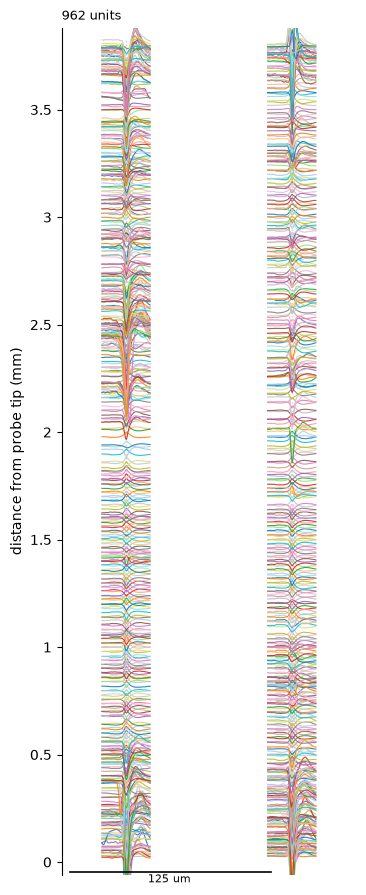

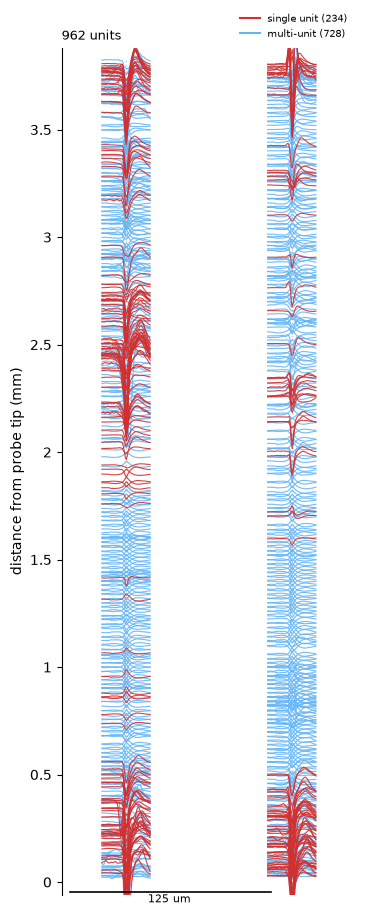

In [52]:
# Each unit's measured mean waveform at its place on the probe -- from the export folder alone.
# One colour per unit, then single units red and multi-units light blue (drawn last, on top).
GLYPH_WIDTH_UM, GLYPH_HEIGHT_UM = 30.0, 40.0      # glyph width; height of the median unit

with h5py.File(SPIKES_MAT, "r") as f:            # waveforms and their unit ids, then closed
    s = f["sorted_spikes"]
    waves = s["MeanWaveform"][()]                # (samples, units)
    wave_unit_ids = s["info/MeanWaveform_Unit_No"][()].ravel().astype(int)
placed = pd.read_csv(SPIKES_MAT.parent / "units.csv").set_index("unit_id")       # x_um, y_um, label
sites = pd.read_csv(SPIKES_MAT.parent / "channel_positions.csv")                  # channel, x_um, y_um

# Join waveform columns to unit rows by unit_id; units with no position stay out.
column = {u: k for k, u in enumerate(wave_unit_ids)}
has_xy = placed[["x_um", "y_um"]].notna().all(axis=1)
drawn = [u for u in placed.index if u in column and has_xy[u]]
ptp = np.ptp(waves, axis=0)
scale = GLYPH_HEIGHT_UM / np.median(ptp[ptp > 0])           # um per waveform unit, one for all
offsets = np.linspace(-GLYPH_WIDTH_UM / 2, GLYPH_WIDTH_UM / 2, waves.shape[0])
kind_of = placed["label"].map({"good": "single unit", "mua": "multi-unit"}).fillna("other")
kind_colour = {"single unit": "#d32f2f", "multi-unit": "#64b5f6"}
print(f"{len(drawn)} of {len(placed)} units drawn; {len(sites)} electrodes")

for colour_by in ("unit", "kind"):
    fig, ax = plt.subplots(figsize=(3.8, 11))
    ax.scatter(sites["x_um"], sites["y_um"], s=2, color="0.85", linewidths=0)
    order = drawn if colour_by == "unit" else sorted(drawn, key=lambda u: kind_of[u] == "single unit")
    for k, u in enumerate(order):
        w = waves[:, column[u]]
        colour = plt.cm.tab20(k % 20) if colour_by == "unit" else kind_colour.get(kind_of[u], "0.6")
        ax.plot(placed.loc[u, "x_um"] + offsets, placed.loc[u, "y_um"] + scale * w,
                color=colour, lw=0.8, alpha=0.9)
    if colour_by == "kind":
        for name, colour in kind_colour.items():
            ax.plot([], [], color=colour, label=f"{name} ({sum(kind_of[u] == name for u in drawn)})")
        ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), fontsize=7, frameon=False)
    x_lo, y_lo = sites["x_um"].min() - 40, sites["y_um"].min() - 60
    ax.set_xlim(x_lo, sites["x_um"].max() + 40)
    ax.set_ylim(y_lo, sites["y_um"].max() + 60)
    ax.plot([x_lo + 5, x_lo + 130], [y_lo + 15] * 2, color="k", lw=1.2)        # 125 um scale bar
    ax.text(x_lo + 67, y_lo + 5, "125 um", ha="center", va="top", fontsize=8)
    ax.set_title(f"{len(placed):,} units", fontsize=9, loc="left")
    ax.set_xticks([])
    for side in ("top", "right", "bottom"):
        ax.spines[side].set_visible(False)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:g}"))
    ax.set_ylabel("distance from probe tip (mm)")
    plt.show()

## 4. Firing-rate distribution

In [ ]:
print(units.groupby("kind")["rate_hz"].describe().round(2), "\n")

edges = np.logspace(np.log10(units["rate_hz"].min() * 0.9), np.log10(units["rate_hz"].max() * 1.1), 30)
plt.figure(figsize=(9, 4))
for k in counts.index:
    plt.hist(units.loc[units["kind"] == k, "rate_hz"], bins=edges, histtype="step", linewidth=2, label=k)
plt.xscale("log")
plt.xlabel("firing rate (Hz)")
plt.ylabel("units")
plt.legend()
plt.show()

## 5. A few random examples

`N_EXAMPLES` units of each kind: mean waveform ± std, ISI histogram (dashed line at 1.5 ms -- a
single unit has almost nothing left of it), and firing rate over time in 60 s bins.

In [ ]:
N_EXAMPLES = 4
SEED = 0              # change it to see other units

if has_waves:                                         # read in section 1
    t_ms = (np.arange(mean_wave.shape[0]) - mean_wave.shape[0] // 2) / fs * 1000

rng = np.random.default_rng(SEED)
for kind in counts.index:
    ids = units.loc[units["kind"] == kind, "unit_id"].to_numpy()
    ids = rng.choice(ids, size=min(N_EXAMPLES, ids.size), replace=False)
    fig, axes = plt.subplots(len(ids), 3, figsize=(14, 2.4 * len(ids)), squeeze=False,
                             gridspec_kw={"width_ratios": [1, 1.2, 2]})
    for (ax_w, ax_i, ax_r), u in zip(axes, ids):
        t = np.sort(times[spike_unit == u])
        row = units.set_index("unit_id").loc[u]

        if has_waves and u in wave_ids:
            w, sd = mean_wave[:, wave_ids.index(u)], std_wave[:, wave_ids.index(u)]
            ax_w.plot(t_ms, w, color="k")
            ax_w.fill_between(t_ms, w - sd, w + sd, color="k", alpha=0.2)
            ax_w.set_ylabel(wave_unit)
        ax_w.set_xlabel("time (ms)")
        ax_w.set_title(f"unit {u}, ch {row['channel']:.0f}", fontsize=9, loc="left")

        isi_ms = np.diff(t) * 1000
        ax_i.hist(isi_ms[isi_ms < 50], bins=np.arange(0, 50.5, 0.5), color="0.3")
        ax_i.axvline(1.5, color="crimson", linestyle="--")
        ax_i.set_xlabel("ISI (ms)")
        ax_i.set_title(f"ISI < 1.5 ms: {np.mean(isi_ms < 1.5):.2%}", fontsize=9, loc="left")

        rate, bin_edges = np.histogram(t, bins=np.arange(t.min(), t.max() + 60, 60))
        ax_r.plot(bin_edges[:-1] + 30, rate / 60)
        ax_r.set_ylim(bottom=0)
        ax_r.set_xlabel("time (s)")
        ax_r.set_ylabel("rate (Hz)")
        ax_r.set_title(f"{row['n_spikes']:,} spikes, {row['rate_hz']:.2f} Hz", fontsize=9, loc="left")
    fig.suptitle(f"{kind}: {len(ids)} of {int(counts[kind])}")
    plt.tight_layout()
    plt.show()

## 6. LFP: a few traces and their spectrogram

`lfp.data` is int16, MATLAB size nChan x nSamples, at `fs` (2500 Hz / `lfp_decimate`).
Microvolts = `data * uv_per_digit` per channel; row `sy_index` is the SY word, not a channel.
Sample `k` is at `t0 + k / fs` seconds on the probe's clock.

The window is in **seconds from the start of the recording**. The spectrogram resolves
`1 / SPEC_SEGMENT_S` Hz, so the window should be several segments long.

In [ ]:
LFP_WINDOW_S = (60.0, 100.0)      # (start, stop), seconds
LFP_CHANNELS = [0, 100, 200, 300] # rows of the LF binary
SPEC_SEGMENT_S = 1.0              # 1 s segments -> 1 Hz resolution
FREQ_RANGE_HZ = (1, 150)

assert LFP_MAT is not None, "no LFP file named: set LFP_MAT at the top (export_lfp: true in the session writes one)"
with h5py.File(LFP_MAT, "r") as f:               # closed when the block ends
    lf = f["lfp"]
    print(LFP_MAT.name)
    for name in lf:
        value = lf[name][()] if lf[name].size <= 4 or lf[name].attrs["MATLAB_class"] == b"char" else None
        if lf[name].attrs["MATLAB_class"] == b"char":
            value = "".join(map(chr, value.ravel()))
        elif value is None:
            value = f"[{' x '.join(map(str, lf[name].shape[::-1]))}]"
        elif value.size == 1:
            value = value.item()
        print(f"  {name:20} {str(value)[:90]}")
    lfp_fs = lf["fs"][()].item()
    t0 = lf["t0"][()].item()
    uv_per_digit = lf["uv_per_digit"][()].ravel()

In [ ]:
k0, k1 = int((LFP_WINDOW_S[0] - t0) * lfp_fs), int((LFP_WINDOW_S[1] - t0) * lfp_fs)

with h5py.File(LFP_MAT, "r") as f:                  # only the window is read, then closed
    raw = f["lfp/data"][k0:k1, :]                   # (samples, channels)
lfp_uv = raw[:, LFP_CHANNELS] * uv_per_digit[LFP_CHANNELS]
lfp_t = t0 + np.arange(k0, k1) / lfp_fs
print(f"{lfp_uv.shape[0]:,} samples x {len(LFP_CHANNELS)} channels, {lfp_t[0]:.1f}-{lfp_t[-1]:.1f} s")

spacing = 1.2 * np.ptp(np.percentile(lfp_uv, [0.5, 99.5], axis=0), axis=0).max()
plt.figure(figsize=(14, 1.2 * len(LFP_CHANNELS) + 1.5))
for i, ch in enumerate(LFP_CHANNELS):
    plt.plot(lfp_t, lfp_uv[:, i] - np.median(lfp_uv[:, i]) + i * spacing, lw=0.5, color="0.15")
plt.yticks(np.arange(len(LFP_CHANNELS)) * spacing, [f"ch {c}" for c in LFP_CHANNELS])
plt.xlabel("time (s)")
plt.title(f"LFP, traces {spacing:.0f} uV apart")
plt.show()

In [ ]:
fig, axes = plt.subplots(len(LFP_CHANNELS), 2, figsize=(14, 2.4 * len(LFP_CHANNELS)), squeeze=False,
                         sharex="col", gridspec_kw={"width_ratios": [3, 1]}, constrained_layout=True)
nperseg = int(SPEC_SEGMENT_S * lfp_fs)
for (ax_s, ax_p), i, ch in zip(axes, range(len(LFP_CHANNELS)), LFP_CHANNELS):
    x = lfp_uv[:, i] - lfp_uv[:, i].mean()
    freq, seg_t, power = signal.spectrogram(x, fs=lfp_fs, nperseg=nperseg, noverlap=nperseg // 2)
    keep = (freq >= FREQ_RANGE_HZ[0]) & (freq <= FREQ_RANGE_HZ[1])
    mesh = ax_s.pcolormesh(lfp_t[0] + seg_t, freq[keep], 10 * np.log10(power[keep]), shading="nearest")
    fig.colorbar(mesh, ax=ax_s, label="dB")
    ax_s.set_ylabel(f"ch {ch}\nfrequency (Hz)")

    freq, psd = signal.welch(x, fs=lfp_fs, nperseg=nperseg)
    keep = (freq >= FREQ_RANGE_HZ[0]) & (freq <= FREQ_RANGE_HZ[1])
    ax_p.semilogy(freq[keep], psd[keep], color="0.2")
    ax_p.set_ylabel("PSD (uV^2/Hz)")
axes[-1, 0].set_xlabel("time (s)")
axes[-1, 1].set_xlabel("frequency (Hz)")
plt.show()